# Session 3 — Data Preparation for Machine Learning Projects
**Code in class** · Computer Vision & Speech Recognition · Joshua Cole

The code from class, executed on the full MILK10k download (10,480 images, 5,240 lesions) rather than the 10-image sample
the course repo ships with. The only change to the class code is the data location (`data/raw/milk10k/`).

In [1]:
import os
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

# repo root = the first parent that contains the raw MILK10k download
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "data" / "raw" / "milk10k" / "metadata.csv").is_file())
DATA_DIR = ROOT / "data" / "raw" / "milk10k"
METADATA_PATH = DATA_DIR / "metadata.csv"                 # per IMAGE
GT_PATH = DATA_DIR / "supplements" / "training_gt.csv"    # per LESION (one-hot diagnosis)

IMG_DIR = Path(os.environ.get("MILK10K_IMAGES_DIR", DATA_DIR / "images"))

def image_path(isic_id: str) -> Path:
    """isic_id -> path of the .jpg file under IMG_DIR."""
    return IMG_DIR / f"{isic_id}.jpg"

def available_subset(df: pd.DataFrame) -> pd.DataFrame:
    """Keep only the rows whose image file exists on disk (a no-op with the full dataset)."""
    mask = df["isic_id"].apply(lambda iid: image_path(iid).exists())
    return df[mask].reset_index(drop=True)

def dominant_class(gt: pd.DataFrame) -> pd.Series:
    """gt is one-hot with exactly one positive class per lesion -> one string label per lesion."""
    return gt.drop(columns="lesion_id").idxmax(axis=1)

def imbalance_ratio(gt: pd.DataFrame, lesion_ids: Optional[pd.Series] = None) -> float:
    """max class count / min class count, computed on a given subset of lesions."""
    sub = gt if lesion_ids is None else gt[gt["lesion_id"].isin(set(lesion_ids))]
    counts = sub.drop(columns="lesion_id").sum()
    counts = counts[counts > 0]
    return float(counts.max() / counts.min())

print("Images folder :", IMG_DIR.relative_to(ROOT))
print("Sample only?  :", IMG_DIR == ROOT / "data" / "images")

Images folder : data/raw/milk10k/images
Sample only?  : False


## Why data preparation matters + MILK10k recap

In [2]:
df = pd.read_csv(METADATA_PATH)   # per IMAGE  (10,480 rows)
gt = pd.read_csv(GT_PATH)          # per LESION (5,240 rows, one-hot diagnosis)
print("metadata:", df.shape, "| gt:", gt.shape)
print("unique lesions:", df["lesion_id"].nunique())

# Exactly 2 images per lesion?
print("\nimages per lesion:")
print(df.groupby("lesion_id").size().value_counts())
print("\nimage types:")
print(df["image_type"].value_counts())
df.head(3)

metadata: (10480, 17) | gt: (5240, 12)
unique lesions: 5240

images per lesion:
2    5240
Name: count, dtype: int64

image types:
image_type
dermoscopic           5240
clinical: close-up    5240
Name: count, dtype: int64


,isic_id,attribution,copyright_license,age_approx,anatom_site_general,anatom_site_special,concomitant_biopsy,diagnosis_1,diagnosis_2,diagnosis_3,diagnosis_4,diagnosis_confirm_type,image_manipulation,image_type,lesion_id,melanocytic,sex
0,ISIC_0051817,MILK study team,CC-BY-NC,70.0,upper extremity,NaN,True,Malignant,Malignant epidermal proliferations,"Squamous cell carcinoma, Invasive",NaN,histopathology,instrument only,dermoscopic,IL_1612768,NaN,male
1,ISIC_0073863,MILK study team,CC-BY-NC,5.0,NaN,NaN,True,Benign,Benign melanocytic proliferations,Nevus,"Nevus, Reed",histopathology,instrument only,dermoscopic,IL_2547802,True,female
2,ISIC_0075884,MILK study team,CC-BY-NC,10.0,upper extremity,NaN,True,Benign,Benign melanocytic proliferations,Nevus,"Nevus, Acral",histopathology,instrument only,clinical: close-up,IL_9270970,True,female


## Train / Validation / Test — three jobs

| Split | Used for | Touched |
|---|---|---|
| Train | fitting weights | every step |
| Validation | tuning, choosing epochs, comparing models | every epoch |
| Test | one honest final estimate | once |

The rule to remember: if you tune on test, it becomes a validation set.

## The group-leakage trap
What goes wrong if we split image by image? Do the naive thing and measure the damage.

In [3]:
from sklearn.model_selection import train_test_split

# NAIVE: split rows (images), stratified on diagnosis_1
naive_train, naive_test = train_test_split(
    df, test_size=0.2, stratify=df["diagnosis_1"], random_state=0
)
leaked = set(naive_train["lesion_id"]) & set(naive_test["lesion_id"])
n_test_lesions = naive_test["lesion_id"].nunique()
print(f"Lesions present in BOTH train and test: {len(leaked)}")
print(f"That is {len(leaked) / n_test_lesions:.0%} of the test lesions -> the model has already 'seen' them.")

Lesions present in BOTH train and test: 1664
That is 89% of the test lesions -> the model has already 'seen' them.


## MILK10k class distribution (real numbers)

,lesions,% of total
BCC,2522,48.1
NV,746,14.2
BKL,544,10.4
SCCKA,473,9.0
MEL,450,8.6
AKIEC,303,5.8
DF,52,1.0
INF,50,1.0
VASC,47,0.9
BEN_OTH,44,0.8


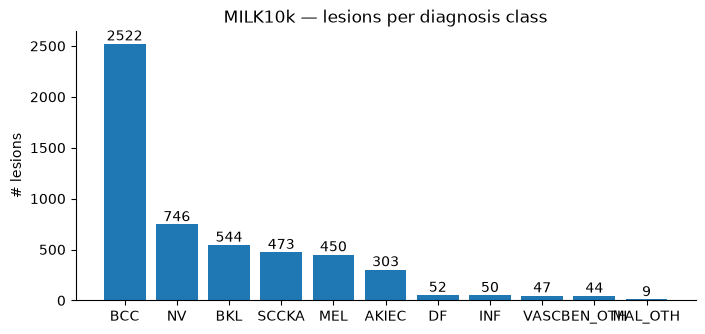

In [4]:
class_cols = [c for c in gt.columns if c != "lesion_id"]
dist = gt[class_cols].sum().sort_values(ascending=False).astype(int)
table = pd.DataFrame({"lesions": dist, "% of total": (100 * dist / len(gt)).round(1)})
display(table)

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(table.index, table["lesions"], color="tab:blue")
ax.bar_label(bars)
ax.set_ylabel("# lesions")
ax.set_title("MILK10k — lesions per diagnosis class")
plt.show()

## Why is MILK10k so imbalanced? (sampling bias)
Most lesions were biopsied: doctors biopsy what worries them, so this is not the real-world prevalence.

In [5]:
lesions = df.drop_duplicates("lesion_id")
print("diagnosis_1 (per lesion):")
print((lesions["diagnosis_1"].value_counts(normalize=True) * 100).round(1))
print("\ndiagnosis_confirm_type (per image):")
print((df["diagnosis_confirm_type"].value_counts(normalize=True) * 100).round(1))

diagnosis_1 (per lesion):
diagnosis_1
Malignant        69.4
Benign           28.3
Indeterminate     2.3
Name: proportion, dtype: float64

diagnosis_confirm_type (per image):
diagnosis_confirm_type
histopathology                            95.7
single contributor clinical assessment     4.3
Name: proportion, dtype: float64


## Metrics that survive imbalance
With ~48 % BCC, a model that always predicts BCC looks "okay" on accuracy and is useless.

In [6]:
from sklearn.metrics import accuracy_score, f1_score

y = dominant_class(gt)          # one label per lesion, e.g. 'BCC'
y_dummy = pd.Series("BCC", index=y.index)   # a "model" that always says BCC
print(f"accuracy : {accuracy_score(y, y_dummy):.3f}   <- looks decent...")
print(f"macro-F1 : {f1_score(y, y_dummy, average='macro', zero_division=0):.3f}   <- reveals the truth")

accuracy : 0.481   <- looks decent...
macro-F1 : 0.059   <- reveals the truth


## The cost of errors is not symmetric
A missed melanoma (false negative) is far worse than an unnecessary biopsy (false positive). Look at per-class recall, not just the average.

In [7]:
from sklearn.metrics import classification_report

report = classification_report(y, y_dummy, zero_division=0, output_dict=True)
print(f"Recall on MEL: {report['MEL']['recall']:.2f}   <- every melanoma missed")
print(f"Recall on BCC: {report['BCC']['recall']:.2f}")

# Illustrative (made-up) costs: the operating point is a *clinical* decision
COST_FN, COST_FP = 100, 1
n_mel = int((y == "MEL").sum())
print(f"\nIllustrative cost of the always-BCC model on melanomas alone: {n_mel} misses x {COST_FN} = {n_mel * COST_FN}")

Recall on MEL: 0.00   <- every melanoma missed
Recall on BCC: 1.00

Illustrative cost of the always-BCC model on melanomas alone: 450 misses x 100 = 45000


## Strategies for class imbalance
Class weights · oversampling · undersampling · targeted augmentation · stratified splitting.

In [8]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array(sorted(y.unique()))
counts = y.value_counts()

# 1) CLASS WEIGHTS: rare class => bigger weight in the loss
weights = compute_class_weight("balanced", classes=classes, y=y)
print(pd.Series(weights, index=classes).round(2).sort_values(ascending=False))

MAL_OTH    52.93
BEN_OTH    10.83
VASC       10.14
INF         9.53
DF          9.16
AKIEC       1.57
MEL         1.06
SCCKA       1.01
BKL         0.88
NV          0.64
BCC         0.19
dtype: float64


In [9]:
# 2) OVERSAMPLING: sample lesions with probability ~ 1 / class_count  (this is with replacement)
sample_w = y.map(1.0 / counts)
oversampled = y.sample(n=len(y), replace=True, weights=sample_w, random_state=0)
print("Oversampled class counts (roughly uniform now, but rare-class rows are REPEATED):")
print(oversampled.value_counts().sort_index())

# 3) UNDERSAMPLING: cut every class down to the smallest one
n_min = counts.min()
print(f"\nUndersampling to {n_min}/class keeps only {n_min * len(counts)} of {len(y)} lesions -> throws data away")

Oversampled class counts (roughly uniform now, but rare-class rows are REPEATED):
AKIEC      492
BCC        460
BEN_OTH    490
BKL        479
DF         476
INF        468
MAL_OTH    483
MEL        472
NV         473
SCCKA      444
VASC       503
Name: count, dtype: int64

Undersampling to 9/class keeps only 99 of 5240 lesions -> throws data away


## Stratified + grouped splitting
Group by `lesion_id` and stratify by diagnosis: `StratifiedGroupKFold`.

### Cross-validation for rare classes
With rare classes (DF: 52, MAL_OTH: 9) a single split may leave a class out. k-fold rotates the held-out fold so every lesion is validated exactly once.

In [10]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
fold_counts, seen = {}, []
for k, (tr_idx, va_idx) in enumerate(sgkf.split(gt, y, groups=gt["lesion_id"])):
    fold_counts[f"fold {k}"] = y.iloc[va_idx].value_counts()
    seen.extend(gt["lesion_id"].iloc[va_idx])

# Every lesion validated exactly once:
assert len(seen) == len(set(seen)) == len(gt)

# Validation-class counts per fold — notice the rare classes still show up in every fold
pd.DataFrame(fold_counts).fillna(0).astype(int).loc[classes]

,fold 0,fold 1,fold 2,fold 3,fold 4
AKIEC,61,60,61,61,60
BCC,505,504,504,504,505
BEN_OTH,9,9,9,9,8
BKL,108,109,109,109,109
DF,10,11,10,10,11
INF,10,10,10,10,10
MAL_OTH,1,2,2,2,2
MEL,90,90,90,90,90
NV,150,149,149,149,149
SCCKA,94,95,95,94,95


## What is data leakage? (types)

| Type | Example |
|---|---|
| Group | same `lesion_id` in train and test |
| Preprocessing | normalising with mean/std computed on all data |
| Duplicate | near-identical re-photographs on both sides |
| Target | a feature that encodes the label |

Below: preprocessing leakage and target leakage.

In [11]:
# --- Preprocessing leakage: statistics must come from TRAIN only ---
tr_idx, te_idx = next(sgkf.split(gt, y, groups=gt["lesion_id"]))
train_l = set(gt["lesion_id"].iloc[tr_idx])
test_l = set(gt["lesion_id"].iloc[te_idx])

avail = available_subset(df)          # only images that exist on disk
tr_sample = avail[avail["lesion_id"].isin(train_l)].sample(min(60, avail["lesion_id"].isin(train_l).sum()), random_state=0)
te_sample = avail[avail["lesion_id"].isin(test_l)].sample(min(60, avail["lesion_id"].isin(test_l).sum()), random_state=0)

def mean_rgb(ids):
    means = []
    for iid in ids:
        im = Image.open(image_path(iid))
        im.draft("RGB", (128, 128))           # fast JPEG downscale on load
        means.append(np.asarray(im.convert("RGB").resize((64, 64)), dtype=np.float32).mean(axis=(0, 1)) / 255)
    return np.mean(means, axis=0)

print("CORRECT (train only)  :", mean_rgb(tr_sample["isic_id"]).round(4))
print("LEAKY  (train + test) :", mean_rgb(pd.concat([tr_sample, te_sample])["isic_id"]).round(4))
print("-> the difference is small here, but the *principle* is: the test set must not influence ANY fitted quantity.")

CORRECT (train only)  : [0.6761 0.519  0.4693]
LEAKY  (train + test) : [0.6815 0.5184 0.4629]
-> the difference is small here, but the *principle* is: the test set must not influence ANY fitted quantity.


In [12]:
# --- Target leakage: does a column secretly encode the label? ---
print((pd.crosstab(df["diagnosis_confirm_type"], df["diagnosis_1"], normalize="index") * 100).round(1))
print("\nIf a column predicts the label this strongly, it is NOT available at prediction time -> don't use it as an input.")

diagnosis_1                             Benign  Indeterminate  Malignant
diagnosis_confirm_type                                                  
histopathology                            25.7            2.0       72.3
single contributor clinical assessment    87.1           10.7        2.2

If a column predicts the label this strongly, it is NOT available at prediction time -> don't use it as an input.


## Case study — shortcut learning in medical imaging
Models can learn acquisition artefacts (scanner, ruler, pen ink) instead of pathology. Check whether such fields correlate with the label.

In [13]:
print("image_manipulation vs diagnosis_1 (row %):")
print((pd.crosstab(df["image_manipulation"].fillna("none"), df["diagnosis_1"], normalize="index") * 100).round(1))
print("\nimage_type vs diagnosis_1 (row %):")
print((pd.crosstab(df["image_type"], df["diagnosis_1"], normalize="index") * 100).round(1))

image_manipulation vs diagnosis_1 (row %):
diagnosis_1         Benign  Indeterminate  Malignant
image_manipulation                                  
altered               39.7           12.8       47.5
instrument only       27.9            2.0       70.1

image_type vs diagnosis_1 (row %):
diagnosis_1         Benign  Indeterminate  Malignant
image_type                                          
clinical: close-up    28.3            2.3       69.4
dermoscopic           28.3            2.3       69.4


## Data-quality checks before you split
Audit missingness first. A NaN is only a bug if the field should always be populated.

In [14]:
miss = df.isna().sum()
audit = pd.DataFrame({"missing": miss, "% missing": (100 * miss / len(df)).round(1)})
audit = audit[audit["missing"] > 0].sort_values("missing", ascending=False)
display(audit)

,missing,% missing
anatom_site_special,10274,98.0
diagnosis_4,8958,85.5
melanocytic,8088,77.2
anatom_site_general,3912,37.3
diagnosis_3,158,1.5
age_approx,40,0.4


In [15]:
# Actions from the slide
clean = df.copy()
clean["age_approx"] = clean["age_approx"].fillna(clean["age_approx"].median())   # numeric -> median
clean["anatom_site_general"] = clean["anatom_site_general"].fillna("unknown")    # categorical -> explicit level
# diagnosis_4 / melanocytic: NaN = "not applicable" -> leave alone
print(clean[["age_approx", "anatom_site_general"]].isna().sum())

age_approx             0
anatom_site_general    0
dtype: int64


## Augmentation — why and what
Label-preserving transforms: flip · rotate · brightness/contrast · crop/zoom. Train set only.

### Real augmentations on a MILK10k image

ISIC_0051817 | dermoscopic | Malignant | size: (600, 450)


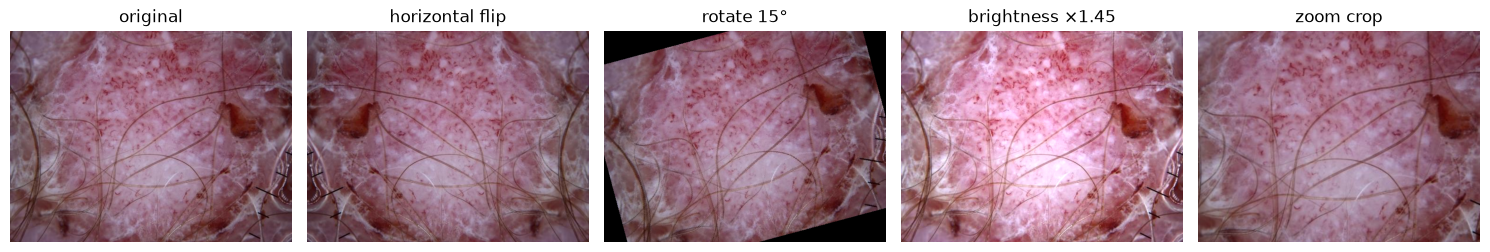

In [16]:
import torchvision.transforms.functional as TF

sample = available_subset(df).iloc[0]
img = Image.open(image_path(sample["isic_id"])).convert("RGB")
print(sample["isic_id"], "|", sample["image_type"], "|", sample["diagnosis_1"], "| size:", img.size)

w, h = img.size
variants = {
    "original":        img,
    "horizontal flip": TF.hflip(img),
    "rotate 15°":      TF.rotate(img, 15),
    "brightness ×1.45": TF.adjust_brightness(img, 1.45),
    "zoom crop":       TF.resized_crop(img, top=h // 10, left=w // 10, height=int(h * 0.8), width=int(w * 0.8), size=(h, w)),
}
fig, axes = plt.subplots(1, len(variants), figsize=(3 * len(variants), 3))
for ax, (name, im) in zip(axes, variants.items()):
    ax.imshow(im); ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()

### Augmentation cautions for medical images
Vertical flip: fine for skin (no canonical "up"), wrong for X-rays. Aggressive colour jitter is dangerous: redness and
pigmentation are diagnostic. Crops must not cut the lesion out. Compare a conservative jitter with an aggressive one:

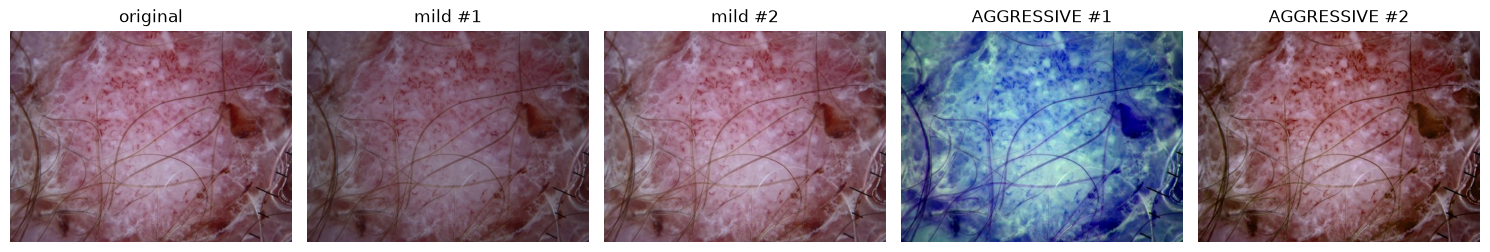

Hue shifts of +-0.5 turn skin green/blue -- no longer a plausible lesion. Every augmentation is a claim: 'this never changes the label'.


In [17]:
import torch
import torchvision.transforms as T

torch.manual_seed(0)
mild = T.ColorJitter(brightness=0.3, contrast=0.2, saturation=0.15)
aggressive = T.ColorJitter(brightness=0.6, contrast=0.6, saturation=0.9, hue=0.5)
panels = {"original": img,
          "mild #1": mild(img), "mild #2": mild(img),
          "AGGRESSIVE #1": aggressive(img), "AGGRESSIVE #2": aggressive(img)}
fig, axes = plt.subplots(1, len(panels), figsize=(3 * len(panels), 3))
for ax, (name, im) in zip(axes, panels.items()):
    ax.imshow(im); ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()
print("Hue shifts of +-0.5 turn skin green/blue -- no longer a plausible lesion. Every augmentation is a claim: 'this never changes the label'.")

## A robust pipeline — the order matters
**Load + validate → Group + stratify split → Freeze test set → Augment (train only) → Dataset / DataLoader**

Takeaways: (1) split on the grouping unit (`lesion_id`), not the row; (2) MILK10k is imbalanced by construction, so accuracy
misleads; (3) `StratifiedGroupKFold` is leak-free and class-balanced; (4) leakage is silent, so suspiciously good results
deserve an audit; (5) augmentations must respect the medical meaning of the image.

### Recap — loading MILK10k
`df` is per image, `gt` is per lesion (one-hot). They share `lesion_id`.

In [18]:
df = pd.read_csv(METADATA_PATH)
gt = pd.read_csv(GT_PATH)
print(df.shape, gt.shape)
print(df["lesion_id"].nunique(), "unique lesions")

(10480, 17) (5240, 12)
5240 unique lesions


### A grouped, stratified split
`idxmax` turns the one-hot columns into a single dominant class per lesion (used for stratification). We split at lesion level, and only afterwards join back to images.

In [19]:
from sklearn.model_selection import StratifiedGroupKFold

y = gt.drop(columns="lesion_id").idxmax(axis=1)   # dominant class per lesion
groups = gt["lesion_id"]
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
train_idx, test_idx = next(sgkf.split(gt, y, groups))
train_lesions = set(gt.loc[train_idx, "lesion_id"])
test_lesions = set(gt.loc[test_idx, "lesion_id"])
print(len(train_lesions), "train lesions |", len(test_lesions), "test lesions")

4192 train lesions | 1048 test lesions


### Verify zero leakage
Trust, but verify: never skip the assert.

In [20]:
overlap = train_lesions & test_lesions
assert len(overlap) == 0, f"LEAKAGE: {len(overlap)} lesions in both splits!"

train_df = df[df["lesion_id"].isin(train_lesions)]
test_df = df[df["lesion_id"].isin(test_lesions)]
print(f"train: {len(train_df)} images / {len(train_lesions)} lesions")
print(f"test:  {len(test_df)} images / {len(test_lesions)} lesions")
assert len(train_df) == 2 * len(train_lesions) and len(test_df) == 2 * len(test_lesions)

train: 8384 images / 4192 lesions
test:  2096 images / 1048 lesions


In [21]:
# Bonus: stratification worked? Class proportions should be ~equal in both splits
props = pd.DataFrame({
    "train %": y.loc[train_idx].value_counts(normalize=True) * 100,
    "test %":  y.loc[test_idx].value_counts(normalize=True) * 100,
}).round(1)
props

,train %,test %
AKIEC,5.8,5.8
BCC,48.1,48.2
BEN_OTH,0.8,0.9
BKL,10.4,10.3
DF,1.0,1.0
INF,1.0,1.0
MAL_OTH,0.2,0.1
MEL,8.6,8.6
NV,14.2,14.3
SCCKA,9.0,9.0


### Quantifying imbalance
One number for the problem. Compute it on the train split only: never peek at test proportions.

BCC        2017
NV          596
BKL         436
SCCKA       379
MEL         360
AKIEC       242
DF           42
INF          40
VASC         37
BEN_OTH      35
MAL_OTH       8
dtype: int64

imbalance ratio (max/min class) = 252.1x


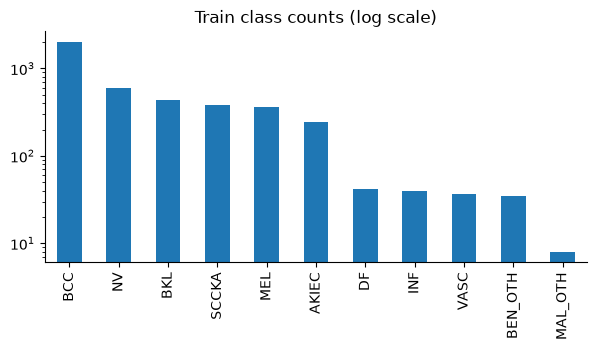

In [22]:
counts = (gt.loc[gt["lesion_id"].isin(train_lesions), gt.columns.drop("lesion_id")]
            .sum().sort_values(ascending=False))
ratio = counts.max() / counts.min()
print(counts)
print(f"\nimbalance ratio (max/min class) = {ratio:.1f}x")

counts.plot.bar(logy=True, figsize=(7, 3), title="Train class counts (log scale)")
plt.show()

## Basic data-quality checks
`Image.verify()` catches truncated / corrupt files without fully decoding them.

In [23]:
from PIL import UnidentifiedImageError

avail = available_subset(df)
n = min(300, len(avail))
bad_files = []
for iid in avail["isic_id"].sample(n, random_state=0):
    try:
        with Image.open(image_path(iid)) as im:
            im.verify()
    except (UnidentifiedImageError, OSError):
        bad_files.append(iid)
print(f"{len(bad_files)} unreadable files out of {n} checked")
print(df[["age_approx", "anatom_site_general"]].isna().mean().round(4))

0 unreadable files out of 300 checked
age_approx             0.0038
anatom_site_general    0.3733
dtype: float64


In [24]:
# Bonus: image sizes — do all images share one resolution? (if not -> we need a resize step)
sizes = [Image.open(image_path(i)).size for i in avail["isic_id"].sample(min(100, len(avail)), random_state=0)]
print(pd.Series(sizes).value_counts().head())

(600, 450)    100
Name: count, dtype: int64


## An augmentation pipeline
Mild, bounded parameters. `eval_transform` has no randomness: validation and test must be reproducible.

In [25]:
import torchvision.transforms as T

train_transform = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=15),
    T.ColorJitter(brightness=0.3, contrast=0.2, saturation=0.15),
    T.RandomResizedCrop(224, scale=(0.85, 1.0)),
    T.ToTensor(),
])
eval_transform = T.Compose([T.Resize((224, 224)), T.ToTensor()])
print(train_transform)

Compose(
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.7, 1.3), contrast=(0.8, 1.2), saturation=(0.85, 1.15), hue=None)
    RandomResizedCrop(size=(224, 224), scale=(0.85, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    ToTensor()
)
